In [7]:
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
import matplotlib.pyplot as plt
from tensorflow.keras import layers,models

In [11]:
size=(224,224)
train_ds=tf.keras.utils.image_dataset_from_directory(r'C:\Users\prath\Downloads\LP IV Updated Datasets\Object Detection\caltech-101',validation_split=0.2,subset='training',seed=42,image_size=size,batch_size=16)
test_ds=tf.keras.utils.image_dataset_from_directory(r'C:\Users\prath\Downloads\LP IV Updated Datasets\Object Detection\caltech-101',validation_split=0.2,subset='validation',seed=42,image_size=size,batch_size=16)
class_names=train_ds.class_names

Found 9144 files belonging to 102 classes.
Using 7316 files for training.
Found 9144 files belonging to 102 classes.
Using 1828 files for validation.


In [13]:
base=VGG16(weights=r'C:\Users\prath\Downloads\LP IV Updated Datasets\Object Detection/vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5',include_top=False,input_shape=(224,224,3))
base.trainable=False
model=models.Sequential([
    layers.Lambda(preprocess_input),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(class_names),activation='softmax')
])
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                      │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ vgg16 (Functional)                   │ (None, 7, 7, 512)           │      14,714,688 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ ?                           │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ ?                           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [14]:
history=model.fit(train_ds.take(100),validation_data=test_ds.take(10),epochs=3)

Epoch 1/3

100/100 ━━━━━━━━━━━━━━━━━━━━ 396s 4s/step - accuracy: 0.1575 - loss: 10.5717 - val_accuracy: 0.3938 - val_loss: 4.7721
Epoch 2/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 418s 4s/step - accuracy: 0.4487 - loss: 4.2390 - val_accuracy: 0.5562 - val_loss: 2.7043
Epoch 3/3
100/100 ━━━━━━━━━━━━━━━━━━━━ 440s 4s/step - accuracy: 0.6225 - loss: 2.2456 - val_accuracy: 0.6500 - val_loss: 2.1803


In [15]:
loss,accuracy=model.evaluate(test_ds.take(10))
print(loss)
print(accuracy)

10/10 ━━━━━━━━━━━━━━━━━━━━ 40s 4s/step - accuracy: 0.6375 - loss: 2.0023
2.002251148223877
0.637499988079071


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 526ms/step


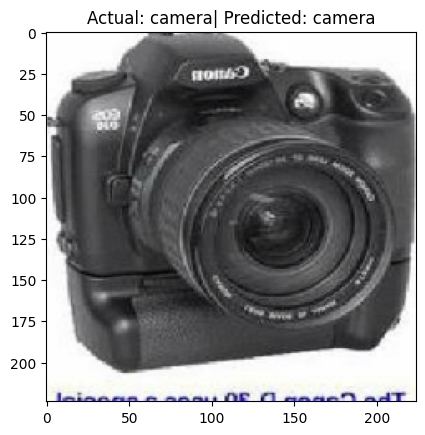

In [23]:
for images,labels in test_ds.take(1):
    prediction=tf.argmax(model.predict(images[:1])[0]).numpy()
    plt.imshow(images[0].numpy().astype('uint8'))
    plt.title('Actual: '+class_names[labels[0]]+"| Predicted: " + class_names[prediction])
    plt.show()


In [ ]:
base.trainable=True
for layer in base.layers[:-6]:
    layer.trainable=False
model.compile(optimizer=Adam(learning_rate=1e-5),loss='sparse_categorical_crossentropy',metrics=['accuracy'])
model.fit(train_ds.take(100),validation_data=test_ds.take(10),epochs=1)

 12/100 ━━━━━━━━━━━━━━━━━━━━ 7:19 5s/step - accuracy: 0.6928 - loss: 1.5427